# Uncertainty-Aware Segmentation in Musculoskeletal Ultrasound
## A pipeline study in preparation for synovitis segmentation in arthritis ultrasound

**Author:** Bhagyaprasad Vastrad
**Date:** October 2026
**Notebook 3 of 3:** deep ensemble and uncertainty analysis

---

## What this notebook does

In notebook 2 I trained one U-Net (Experiment A). Here I ask the question my project is really about: can the model's uncertainty tell me which segmentations I should not trust?

1. I train four more U-Nets that differ only in the random seed. Together with Experiment A they form a deep ensemble of five members.
2. I compare three ways of producing a prediction and an uncertainty score:
   - **Single model:** the entropy of the model's own probabilities (the simple baseline).
   - **Test-time augmentation (TTA):** four passes of one model on the original, flipped, darker and brighter image.
   - **Deep ensemble:** five independently trained models.
3. I turn pixel-level uncertainty into one score per image (mean entropy and mean mutual information).
4. I measure whether those scores predict segmentation errors, using AUROC, rank correlation and risk-coverage curves.
5. I measure calibration at pixel level and at image level.

## Definitions I use
- **Failed segmentation:** per-image Dice below 0.7. This is my placeholder. In a real study I would agree the threshold with clinical collaborators, so I also check 0.5, 0.6 and 0.8.
- **Predictive entropy:** how uncertain the averaged prediction is at each pixel. The maximum is 0.693 (ln 2).
- **Mutual information:** the part of the uncertainty that comes from disagreement between predictions (the model-based part). It is zero if all predictions are identical.
- **Risk-coverage curve:** I sort images from most to least certain, keep only the most certain ones, and track the mean Dice of those kept. If uncertainty is useful, Dice should rise as I keep fewer images.
- **Image-level calibration:** an uncertainty score is not a probability. I fit a logistic mapping from the score to failure on the validation subjects only, then judge the resulting probabilities on the test subjects.

## What I can and cannot claim
- All images come from one scanner at one centre, and this is muscle, not synovitis.
- My ensemble members share the same pretrained encoder weights, the same data and the same split. They differ only in the seed, so their diversity is limited and the ensemble may be less diverse than a real multi-centre one.
- Experiment A used one seed, so before this notebook I had no estimate of training noise.
- I have not run the shift experiments (muscle shift and disease shift) through the uncertainty analysis yet.
- MC dropout is not included: my trained models have no dropout layers, so it needs a separately trained model.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')
import os
os.chdir('/content/drive/MyDrive/arthritis_trust')
print(os.listdir('.'))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['index.xls', 'data_256.npz', 'runs', 'runs.zip']


In [ ]:
!pip install -q xlrd

In [ ]:
# I only need this on Colab. After it finishes I do not restart the runtime.
!pip install -q segmentation-models-pytorch

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 8.7 MB/s eta 0:00:00


In [ ]:
import json, os, time
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import segmentation_models_pytorch as smp
from PIL import Image
from torch.utils.data import DataLoader, Dataset

INDEX = "index.xls"      # the split table from notebook 1 (using .xls format)
OUT_DIR = "runs"         # I save models and results here

# I read images from data_256.npz when it exists (the Colab case).
NPZ_PATH, NPZ_SIZE = "data_256.npz", 256
_ARR = None
if os.path.exists(NPZ_PATH):
    _z = np.load(NPZ_PATH)
    _ARR = {"imgs": _z["imgs"], "msks": _z["msks"]}
    print("Using compact arrays from", NPZ_PATH, _ARR["imgs"].shape)
else:
    print("No", NPZ_PATH, "found: check that the Drive folder is mounted and contains the file")

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


class USData(Dataset):
    def __init__(self, df, size, train):
        self.size, self.train = size, train
        rows = df.index.to_numpy()                # row numbers in index
        self.meta = df.reset_index(drop=True)     # I keep the metadata for the results table
        self.imgs, self.msks = [], []
        for i in rows:
            self.imgs.append(_ARR["imgs"][i])
            self.msks.append(_ARR["msks"][i])

    def __len__(self):
        return len(self.imgs)

    def __getitem__(self, i):
        x = torch.from_numpy(self.imgs[i]).float().div(255).unsqueeze(0)
        y = torch.from_numpy(self.msks[i]).float().unsqueeze(0)
        if self.train:
            if torch.rand(1) < 0.5:                       # random horizontal flip
                x, y = x.flip(-1), y.flip(-1)
            gain = 1 + (torch.rand(1) - 0.5) * 0.2        # brightness gain 0.9 to 1.1
            bias = (torch.rand(1) - 0.5) * 0.1            # intensity shift -0.05 to 0.05
            x = (x * gain + bias).clamp(0, 1)
        return (x - 0.5) / 0.5, y


def dice_per_image(logits, y, eps=1e-6):
    """Per-image Dice at threshold 0.5. If both masks are empty the Dice is 1."""
    p = (torch.sigmoid(logits) > 0.5).float()
    inter = (p * y).sum((1, 2, 3))
    den = p.sum((1, 2, 3)) + y.sum((1, 2, 3))
    return torch.where(den == 0, torch.ones_like(den), 2 * inter / den.clamp(min=eps))


@torch.no_grad()
def evaluate(model, loader):
    """Returns one Dice value per image, in the same order as the dataset."""
    model.eval()
    out = []
    for x, y in loader:
        logits = model(x.to(device))
        out.append(dice_per_image(logits, y.to(device)).cpu())
    return torch.cat(out).numpy()


def run_experiment(name, train_muscles=("BB", "GM", "TA"), train_condition="all", seed=0,
                   epochs=30, patience=6, batch_size=16, img_size=256, lr=3e-4,
                   encoder="resnet34", encoder_weights="imagenet", subsample=None):
    torch.manual_seed(seed)
    np.random.seed(seed)

    df = pd.read_csv(INDEX, dtype={"subject": str})

    def pick(split):
        d = df[(df.split == split) & (df.muscle.isin(train_muscles))]
        if train_condition != "all":
            d = d[d.condition == train_condition]
        return d

    train_df, val_df, test_df = pick("train"), pick("val"), df[df.split == "test"]
    if subsample:
        cap = lambda d: d.sample(n=min(subsample, len(d)), random_state=0)
        train_df, val_df, test_df = cap(train_df), cap(val_df), cap(test_df)
    print(f"Train {len(train_df)}  Val {len(val_df)}  Test {len(test_df)} images")

    t0 = time.time()
    train_ds = USData(train_df, img_size, train=True)
    val_ds = USData(val_df, img_size, train=False)
    test_ds = USData(test_df, img_size, train=False)
    print(f"Loaded in {time.time() - t0:.0f}s")

    mk = lambda ds, shuffle: DataLoader(ds, batch_size=batch_size, shuffle=shuffle,
                                        num_workers=0, pin_memory=(device == "cuda"))
    train_dl, val_dl, test_dl = mk(train_ds, True), mk(val_ds, False), mk(test_ds, False)

    weights = None if str(encoder_weights).lower() == "none" else encoder_weights
    model = smp.Unet(encoder, encoder_weights=weights, in_channels=1, classes=1).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=lr)
    bce, dice_loss = nn.BCEWithLogitsLoss(), smp.losses.DiceLoss("binary")

    run_dir = os.path.join(OUT_DIR, name)
    os.makedirs(run_dir, exist_ok=True)
    best, bad = -1.0, 0

    for ep in range(1, epochs + 1):
        model.train()
        tot = 0.0
        for x, y in train_dl:
            x, y = x.to(device), y.to(device)
            out = model(x)
            loss = bce(out, y) + dice_loss(out, y)
            opt.zero_grad()
            loss.backward()
            opt.step()
            tot += loss.item() * x.size(0)

        val_dice = float(evaluate(model, val_dl).mean())
        print(f"epoch {ep:02d}  train loss {tot / len(train_ds):.4f}  val Dice {val_dice:.4f}")

        if val_dice > best:
            best, bad = val_dice, 0
            torch.save(model.state_dict(), os.path.join(run_dir, "best_model.pth"))
        else:
            bad += 1
            if bad >= patience:
                print("Early stopping")
                break

    model.load_state_dict(torch.load(os.path.join(run_dir, "best_model.pth"), map_location=device))
    dice = evaluate(model, test_dl)
    res = test_ds.meta.copy()
    res["dice"] = dice
    res.to_csv(os.path.join(run_dir, "test_dice.csv"), index=False)

    cfg = dict(name=name, train_muscles=list(train_muscles), train_condition=train_condition,
               seed=seed, epochs=epochs, patience=patience, batch_size=batch_size,
               img_size=img_size, lr=lr, encoder=encoder, encoder_weights=str(encoder_weights),
               subsample=subsample, best_val_dice=best)
    with open(os.path.join(run_dir, "config.json"), "w") as f:
        json.dump(cfg, f, indent=2)

    print(f"\nBest val Dice {best:.4f}   Overall test Dice {dice.mean():.4f}")
    print(res.groupby(["muscle", "condition"]).dice.agg(["count", "mean", "std"]).round(4))
    print(f"\nSaved to {os.path.join(OUT_DIR, name)}")
    return res

Using compact arrays from data_256.npz (8169, 256, 256)
Device: cuda


In [ ]:
import os
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from sklearn.metrics import roc_auc_score
from sklearn.linear_model import LogisticRegression
from scipy.stats import spearmanr

# I check that the setup cells of notebook 2 were run in this session
for name in ["USData", "run_experiment", "INDEX", "OUT_DIR", "device", "smp", "DataLoader"]:
    assert name in globals(), f"{name} is missing: I need to run the setup cells of notebook 2 first"
print("Setup looks fine. Device:", device)

# my Experiment A model must be there (it comes from notebook 2)
p0 = os.path.join(OUT_DIR, "all_s0", "best_model.pth")
print("Experiment A model found:", os.path.exists(p0), "->", os.path.abspath(p0))

Setup looks fine. Device: cuda
Experiment A model found: True -> /content/drive/MyDrive/arthritis_trust/runs/all_s0/best_model.pth


## 1. Training the other four ensemble members

Each model uses exactly the same split and settings as Experiment A. Only the seed changes. I expect this to take roughly 20 to 30 minutes per model on a T4 GPU, so about 1.5 to 2 hours in total. If Colab disconnects, I reconnect, rerun the setup cells and this cell. Finished seeds are skipped.

In [ ]:
SEEDS = [0, 1, 2, 3, 4]      # seed 0 is Experiment A, which I already trained

for s in SEEDS:
    name = f"all_s{s}"
    if os.path.exists(os.path.join(OUT_DIR, name, "test_dice.csv")):
        print(f"{name}: already finished, skipping")
        continue
    print(f"\n######## Training {name} ########")
    run_experiment(name, seed=s)     # same split and settings as Experiment A, only the seed changes

all_s0: already finished, skipping
all_s1: already finished, skipping
all_s2: already finished, skipping
all_s3: already finished, skipping
all_s4: already finished, skipping


## 2. How much does the result change from seed to seed?

This is my first estimate of training noise. It tells me how large a difference between two runs I can believe.

In [ ]:
# How much does the test Dice change from seed to seed? This is my estimate of training noise.
rows = []
for s in SEEDS:
    d = pd.read_csv(os.path.join(OUT_DIR, f"all_s{s}", "test_dice.csv"))
    rows.append(dict(seed=s, test_dice=d.dice.mean()))
seed_tbl = pd.DataFrame(rows)
print(seed_tbl.round(4).to_string(index=False))
print(f"\nMean {seed_tbl.test_dice.mean():.4f}   Std across seeds {seed_tbl.test_dice.std():.4f}")

 seed  test_dice
    0     0.8967
    1     0.8969
    2     0.8963
    3     0.8997
    4     0.8942

Mean 0.8968   Std across seeds 0.0020


## 3. Helper functions

- `entropy_bin`: per-pixel binary entropy.
- `dice_from_prob`: per-image Dice of a probability map thresholded at 0.5 (two empty masks give 1).
- `tta_prob`: the three extra test-time augmentations (flip, darker, brighter).
- `PixelCal`: collects pixel-level calibration statistics (ECE and Brier score) batch by batch, because all test pixels together are too many to hold at once.
- `load_members`: loads the five trained U-Nets.

In [ ]:
EPS = 1e-7

def entropy_bin(p):
    """Binary entropy in nats, per pixel. The maximum is ln 2 = 0.693."""
    p = p.clamp(EPS, 1 - EPS)
    return -(p * torch.log(p) + (1 - p) * torch.log(1 - p))


def dice_from_prob(p, y):
    """Per-image Dice of a thresholded probability map. Two empty masks give a Dice of 1."""
    pred = (p > 0.5).float()
    inter = (pred * y).sum((1, 2, 3))
    den = pred.sum((1, 2, 3)) + y.sum((1, 2, 3))
    return torch.where(den == 0, torch.ones_like(den), 2 * inter / den.clamp(min=1e-6))


def tta_prob(model, x, k):
    """Test-time augmentation k: 1 = horizontal flip, 2 = darker (x0.9), 3 = brighter (x1.1)."""
    if k == 1:
        return torch.sigmoid(model(x.flip(-1))).flip(-1)       # I flip the prediction back
    gain = 0.9 if k == 2 else 1.1
    x01 = (x * 0.5 + 0.5) * gain                              # back to [0, 1], apply the gain
    return torch.sigmoid(model((x01.clamp(0, 1) - 0.5) / 0.5))


class PixelCal:
    """Collects pixel-level calibration statistics over many batches (ECE and Brier score)."""
    def __init__(self, nbins=15):
        self.nb = nbins
        self.cnt = torch.zeros(nbins, dtype=torch.float64, device=device)
        self.sp = torch.zeros(nbins, dtype=torch.float64, device=device)
        self.sy = torch.zeros(nbins, dtype=torch.float64, device=device)
        self.sq, self.n = 0.0, 0

    def add(self, p, y):
        p = p.flatten().double()
        y = y.flatten().double()
        idx = (p * self.nb).long().clamp(max=self.nb - 1)
        self.cnt += torch.bincount(idx, minlength=self.nb).double()
        self.sp += torch.bincount(idx, weights=p, minlength=self.nb)
        self.sy += torch.bincount(idx, weights=y, minlength=self.nb)
        self.sq += float(((p - y) ** 2).sum())
        self.n += p.numel()

    def result(self):
        c = self.cnt.clamp(min=1)
        ece = float((self.cnt / self.cnt.sum() * (self.sy / c - self.sp / c).abs()).sum())
        return ece, self.sq / self.n


def load_members(seeds):
    models = []
    for s in seeds:
        m = smp.Unet("resnet34", encoder_weights=None, in_channels=1, classes=1).to(device)
        m.load_state_dict(torch.load(os.path.join(OUT_DIR, f"all_s{s}", "best_model.pth"), map_location=device))
        models.append(m.eval())
    return models

## 4. Running every method on every image

For each image I get three predictions: the single model (seed 0), TTA on the seed 0 model, and the five-member ensemble. For each I record the per-image Dice and the image-level uncertainty scores (mean predictive entropy for all three, plus mean mutual information for TTA and the ensemble).

I run this on the validation subjects (used only to fit the image-level calibration mapping) and on the test subjects (used for every reported result).

In [ ]:
@torch.no_grad()
def collect(df_split, models, batch_size=32, pixel_cal=False):
    """Runs the single model, TTA (on member 0) and the ensemble on every image of a split.
    Returns one row per image with Dice and image-level uncertainty scores for each method."""
    ds = USData(df_split, 256, train=False)
    dl = DataLoader(ds, batch_size=batch_size, shuffle=False, num_workers=0)
    cal = {k: PixelCal() for k in ("single", "tta", "ens")} if pixel_cal else None
    rec = {k: [] for k in ["dice_single", "dice_tta", "dice_ens", "single_ent",
                           "tta_ent", "tta_mi", "ens_ent", "ens_mi"]}
    for x, y in dl:
        x, y = x.to(device), y.to(device)
        P_ens = torch.stack([torch.sigmoid(m(x)) for m in models])               # (members, B, 1, H, W)
        P_tta = torch.stack([P_ens[0]] + [tta_prob(models[0], x, k) for k in (1, 2, 3)])
        for name, P in (("single", P_ens[:1]), ("tta", P_tta), ("ens", P_ens)):
            pbar = P.mean(0)                                                      # mean probability map
            h_pred = entropy_bin(pbar).mean((1, 2, 3))                            # predictive entropy
            rec[f"dice_{name}"].append(dice_from_prob(pbar, y).cpu())
            rec[f"{name}_ent"].append(h_pred.cpu())
            if name != "single":
                h_exp = entropy_bin(P).mean(0).mean((1, 2, 3))                    # expected entropy
                rec[f"{name}_mi"].append((h_pred - h_exp).clamp(min=0).cpu())     # mutual information
            if cal is not None:
                cal[name].add(pbar, y)
    out = ds.meta.copy()
    for k, v in rec.items():
        out[k] = torch.cat(v).numpy()
    return out, cal

## 5. Collecting the predictions

After this cell I check that member 0 reproduces the Dice I got in Experiment A. If the two numbers differ by more than a tiny amount, something is wrong and I should stop and investigate before reading any result below.

In [ ]:
df = pd.read_csv(INDEX, dtype={"subject": str})
val_df = df[df.split == "val"]
test_df = df[df.split == "test"]

models = load_members(SEEDS)
print(f"Loaded {len(models)} ensemble members")

res_val, _ = collect(val_df, models)
res_test, cal = collect(test_df, models, pixel_cal=True)

res_val.to_csv(os.path.join(OUT_DIR, "uncertainty_val.csv"), index=False)
res_test.to_csv(os.path.join(OUT_DIR, "uncertainty_test.csv"), index=False)

# Consistency check: member 0 here must reproduce the Dice that notebook 2 reported for Experiment A
ref = pd.read_csv(os.path.join(OUT_DIR, "all_s0", "test_dice.csv"))
print(f"\nMember 0 test Dice here: {res_test.dice_single.mean():.4f}   reported in Experiment A: {ref.dice.mean():.4f}")
print(f"Test Dice, single {res_test.dice_single.mean():.4f}   TTA {res_test.dice_tta.mean():.4f}   ensemble {res_test.dice_ens.mean():.4f}")

Loaded 5 ensemble members

Member 0 test Dice here: 0.8911   reported in Experiment A: 0.8967
Test Dice, single 0.8911   TTA 0.8917   ensemble 0.8981


## 6. Metrics

For each uncertainty score I report:
- **AUROC:** if I pick one failed and one successful image at random, how often is the failed one given the higher uncertainty? 0.5 means no information, 1.0 means perfect.
- **Spearman:** rank correlation between uncertainty and error (1 minus Dice).
- **AURC:** area under the risk-coverage curve (lower is better). I also give the oracle value (perfect ordering by true Dice) and the random value (no ordering), so I can see how far the score is between useless and perfect.
- **Dice when keeping the most certain 90%, 80% and 50% of images.**
- **ECE, Brier and Brier skill** of failure probabilities from the logistic mapping fitted on validation data. A Brier skill above 0 means it beats simply predicting the overall failure rate.

Each uncertainty score is compared with the failures of the predictor it belongs to, because the single model, TTA and the ensemble do not fail on exactly the same images.

In [ ]:
def risk_coverage(unc, dice):
    """Keep the most certain images first and track the mean Dice of the images kept."""
    order = np.argsort(unc, kind="stable")
    d = dice[order]
    n = len(d)
    return np.arange(1, n + 1) / n, np.cumsum(d) / np.arange(1, n + 1)


def aurc(unc, dice):
    """Area under the risk-coverage curve, where risk = 1 - mean Dice. Lower is better."""
    _, md = risk_coverage(unc, dice)
    return float(np.mean(1 - md))


def ece_binary(p, y, n_bins=10):
    bins = np.minimum((p * n_bins).astype(int), n_bins - 1)
    e = 0.0
    for b in range(n_bins):
        m = bins == b
        if m.any():
            e += m.mean() * abs(y[m].mean() - p[m].mean())
    return float(e)


def image_level_calibration(s_val, fail_val, s_test, fail_test):
    """I fit a logistic mapping from uncertainty to failure on validation data only,
    then judge the resulting failure probabilities on the test data."""
    if fail_val.sum() < 5 or (1 - fail_val).sum() < 5:
        return np.nan, np.nan, np.nan
    f = lambda s: np.log(s + 1e-8).reshape(-1, 1)
    mu, sd = f(s_val).mean(), f(s_val).std() + 1e-8
    lr = LogisticRegression(C=1.0).fit((f(s_val) - mu) / sd, fail_val)
    p = lr.predict_proba((f(s_test) - mu) / sd)[:, 1]
    brier = float(np.mean((p - fail_test) ** 2))
    ref = float(np.mean((fail_val.mean() - fail_test) ** 2))          # always predicting the base rate
    return ece_binary(p, fail_test), brier, 1 - brier / ref           # skill above 0 beats the base rate


# each uncertainty score is judged against the failures of the predictor it belongs to
METHODS = [
    ("Single model, entropy", "single_ent", "dice_single"),
    ("TTA, entropy", "tta_ent", "dice_tta"),
    ("TTA, mutual information", "tta_mi", "dice_tta"),
    ("Ensemble, entropy", "ens_ent", "dice_ens"),
    ("Ensemble, mutual information", "ens_mi", "dice_ens"),
]


def analyse(d_val, d_test, thr):
    rows = []
    for label, sc, dc in METHODS:
        unc, dice = d_test[sc].values, d_test[dc].values
        fail_t = (dice < thr).astype(int)
        fail_v = (d_val[dc].values < thr).astype(int)
        _, md = risk_coverage(unc, dice)
        n = len(dice)
        at = lambda c: md[int(round(c * n)) - 1]
        auc = roc_auc_score(fail_t, unc) if 0 < fail_t.sum() < n else np.nan
        ece, brier, bss = image_level_calibration(d_val[sc].values, fail_v, unc, fail_t)
        rows.append(dict(method=label, failures=int(fail_t.sum()), AUROC=auc,
                         spearman=spearmanr(unc, 1 - dice)[0],
                         AURC=aurc(unc, dice), AURC_oracle=aurc(-dice, dice),
                         AURC_random=float(np.mean(1 - dice)),
                         dice_all=at(1.0), dice_keep90=at(0.9), dice_keep80=at(0.8), dice_keep50=at(0.5),
                         ECE=ece, Brier=brier, Brier_skill=bss))
    return pd.DataFrame(rows).set_index("method")

## 7. Main results

Failure means Dice below 0.7 (my placeholder threshold). The table shows how many test images fail for each predictor and how well each uncertainty score identifies them.

In [ ]:
pd.set_option("display.width", 250)
pd.set_option("display.max_columns", 30)

FAIL_THR = 0.7     # my placeholder definition of a failed segmentation (Dice below 0.7)

main = analyse(res_val, res_test, FAIL_THR)
print(f"Failure = Dice < {FAIL_THR}.  Test images: {len(res_test)}")
print(main.round(3).to_string())

Failure = Dice < 0.7.  Test images: 1643
                              failures  AUROC  spearman   AURC  AURC_oracle  AURC_random  dice_all  dice_keep90  dice_keep80  dice_keep50    ECE  Brier  Brier_skill
method                                                                                                                                                              
Single model, entropy               59  0.576     0.301  0.118        0.056        0.109     0.891        0.897        0.899        0.903  0.007  0.035        0.002
TTA, entropy                        57  0.606     0.330  0.112        0.056        0.108     0.892        0.898        0.903        0.905  0.008  0.033        0.010
TTA, mutual information             57  0.755     0.383  0.091        0.056        0.108     0.892        0.900        0.904        0.915  0.007  0.032        0.050
Ensemble, entropy                   52  0.741     0.318  0.094        0.051        0.102     0.898        0.906        0.910        0.

## 8. Does the conclusion depend on my failure threshold?

My threshold of 0.7 is arbitrary. If the AUROC changes a lot between thresholds, I should not trust any single number. At strict thresholds there are very few failures, so those AUROC values are noisy.

In [ ]:
# Does the answer depend on where I put the failure threshold?
tbl = {}
for thr in [0.5, 0.6, 0.7, 0.8]:
    t = analyse(res_val, res_test, thr)
    tbl[f"AUROC at {thr}"] = t.AUROC
    tbl[f"fails at {thr}"] = t.failures
print(pd.DataFrame(tbl).round(3).to_string())

                              AUROC at 0.5  fails at 0.5  AUROC at 0.6  fails at 0.6  AUROC at 0.7  fails at 0.7  AUROC at 0.8  fails at 0.8
method                                                                                                                                      
Single model, entropy                0.354            19         0.477            35         0.576            59         0.607           138
TTA, entropy                         0.463            21         0.521            33         0.606            57         0.637           132
TTA, mutual information              0.727            21         0.731            33         0.755            57         0.726           132
Ensemble, entropy                    0.758            20         0.802            30         0.741            52         0.659           115
Ensemble, mutual information         0.845            20         0.876            30         0.827            52         0.711           115


## 9. Risk-coverage curves

If an uncertainty score is useful, the curve rises to the left: keeping only the most certain images should give a higher mean Dice. The dashed line shows the best possible ordering and the dotted line shows what happens with no useful ordering.

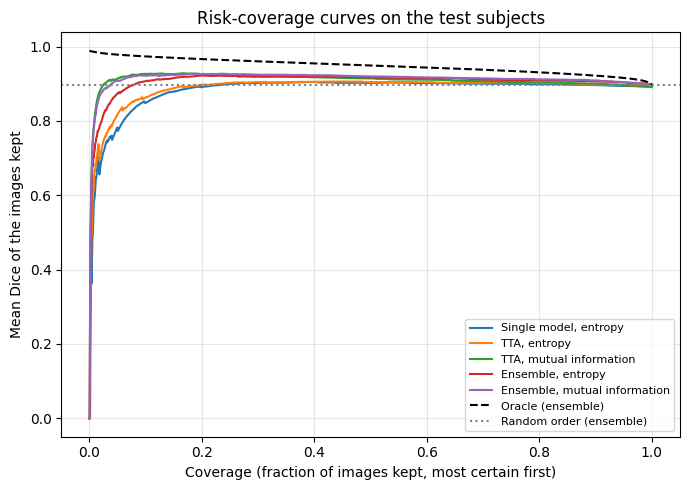

In [ ]:
fig, ax = plt.subplots(figsize=(7, 5))
for label, sc, dc in METHODS:
    cov, md = risk_coverage(res_test[sc].values, res_test[dc].values)
    ax.plot(cov, md, label=label)
cov, md = risk_coverage(-res_test.dice_ens.values, res_test.dice_ens.values)
ax.plot(cov, md, "k--", label="Oracle (ensemble)")
ax.axhline(res_test.dice_ens.mean(), color="gray", linestyle=":", label="Random order (ensemble)")
ax.set_xlabel("Coverage (fraction of images kept, most certain first)")
ax.set_ylabel("Mean Dice of the images kept")
ax.set_title("Risk-coverage curves on the test subjects")
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

## 10. Pixel-level calibration

Here I ask whether the predicted foreground probability matches how often a pixel really is foreground. Most pixels are easy background, so these numbers are dominated by easy pixels and I should read them together with the image-level results, not instead of them.

In [ ]:
rows = []
for name, label in [("single", "Single model"), ("tta", "TTA (4 passes)"), ("ens", "Ensemble (5 members)")]:
    ece, brier = cal[name].result()
    rows.append(dict(method=label, pixel_ECE=ece, pixel_Brier=brier))
print(pd.DataFrame(rows).set_index("method").round(5).to_string())

                      pixel_ECE  pixel_Brier
method                                      
Single model            0.02136      0.02960
TTA (4 passes)          0.01888      0.02868
Ensemble (5 members)    0.01434      0.02665


## 11. The same analysis without subject 1244

In Experiment A, ten of the twenty worst test images came from one biceps subject (ID 1244) whose masks cover only about 0.5% of the image. I do not know yet whether that is an annotation problem or a nearly absent muscle region. I report the results both ways and I do not remove the subject from the main analysis.

In [ ]:
# The same analysis without subject 1244, whose near-empty masks gave Dice close to 0
keep_t = res_test.subject != "1244"
keep_v = res_val.subject != "1244"
print(f"Without subject 1244: {int(keep_t.sum())} test images")
print(analyse(res_val[keep_v], res_test[keep_t], FAIL_THR)[["failures", "AUROC", "spearman", "AURC", "AURC_oracle", "AURC_random", "dice_all", "dice_keep90", "dice_keep80", "Brier_skill"]].round(3).to_string())

Without subject 1244: 1624 test images
                              failures  AUROC  spearman   AURC  AURC_oracle  AURC_random  dice_all  dice_keep90  dice_keep80  Brier_skill
method                                                                                                                                   
Single model, entropy               48  0.676     0.324  0.097        0.056        0.104     0.896        0.903        0.905        0.008
TTA, entropy                        46  0.707     0.352  0.092        0.055        0.103     0.897        0.904        0.909        0.018
TTA, mutual information             46  0.801     0.388  0.081        0.055        0.103     0.897        0.906        0.909        0.061
Ensemble, entropy                   42  0.778     0.322  0.085        0.051        0.097     0.903        0.911        0.914        0.044
Ensemble, mutual information        42  0.846     0.333  0.078        0.051        0.097     0.903        0.911        0.914        0

## 12. How I will read these results

- **Is there any signal?** An AUROC clearly above 0.5, a positive Spearman correlation, and a risk-coverage curve that rises as coverage falls.
- **Does it beat the simple baseline?** I compare the ensemble and TTA scores with the single-model entropy. If they are no better, the extra cost is not justified here.
- **Is it more than mask size?** Failures in this dataset are partly linked to tiny masks. A high AUROC could partly reflect that, so I will look at the failing images before claiming more.
- **Is the ensemble actually diverse?** If mutual information is near zero everywhere, my five members agree almost completely and I should say so.
- **Calibration:** a Brier skill above 0 means the mapped probabilities beat the overall failure rate. A score that ranks well can still be badly calibrated, which is why I report both.

## Limitations I will state in my write-up
- One scanner and one centre, muscle rather than synovitis, and a placeholder failure threshold.
- Ensemble members share data, split and pretrained encoder, so diversity is limited.
- One TTA configuration and no MC dropout yet.
- The shift experiments (muscle shift and disease shift) are not yet analysed for uncertainty.

## Next steps
1. Add MC dropout (train one model with dropout layers).
2. Run the same analysis on the muscle shift and disease shift experiments, asking whether uncertainty rises under shift.
3. Look at the best and worst images with their uncertainty maps.